# Part 2: LSTM Model Training for Electricity Demand Forecasting

**Project:** AI for IoT — Smart Energy Consumption Prediction  
**Objective:** Forecast next 1-minute active power demand ($W$) using 30 consecutive 1-minute multi-feature electrical observations.  
**Stage:** Part 2 — Deep Learning Model Design, Chronological Validation, and Training.  

---

### Workflow Overview
1. **Environment & Imports:** Set up reproducibility seeds and deep learning libraries.
2. **Load Prepared Sequences:** Load the scaled NumPy sequence arrays generated in Part 1.
3. **Verify Dataset Integrity:** Confirm shapes, absence of NaNs, feature ordering, and temporal relationship.
4. **Build LSTM Architecture:** Multi-layer LSTM regression network with Dropout regularization.
5. **Compile Model:** Configure Adam optimizer, Mean Squared Error (MSE) loss, and regression metrics.
6. **Chronological Model Training:** Train on chronological training data with non-shuffled validation split, EarlyStopping, and ReduceLROnPlateau.
7. **Plot Training History:** Visualize loss and MAE convergence curves over epochs.
8. **Save Trained Model:** Persist the best model weights in modern `.keras` format (`lstm_model.keras`).
9. **Save Training Metadata:** Export full training hyperparameters, timestamps, and convergence stats.
10. **Final Model Sanity Check:** Verify inference execution, output bounds, and physical unit inverse scaling.

## 1. Environment and Imports

We import standard scientific computing and deep learning packages (`numpy`, `tensorflow`, `sklearn`, `matplotlib`).  
To guarantee reproducibility, we explicitly seed NumPy and TensorFlow pseudo-random number generators.

In [1]:
import os
import json
import time
import joblib
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Ensure reproducible initialization
np.random.seed(42)
tf.random.set_seed(42)

print("Environment Initialized Successfully.")
print(f"TensorFlow Version: {tf.__version__}")
print(f"NumPy Version: {np.__version__}")
print(f"Joblib Version: {joblib.__version__}")
print("Random seeds set to: 42")

Environment Initialized Successfully.
TensorFlow Version: 2.21.0
NumPy Version: 2.5.3
Joblib Version: 1.6.0
Random seeds set to: 42


## 2. Load Prepared Sequences

In Part 1, continuous 1-minute electrical data was segmented across sampling gaps, standardized using `StandardScaler` fitted **strictly on training observations**, and rolled into 30-timestep sliding windows.  

Here we load the preprocessed arrays:
- `X_train.npy`, `y_train.npy`: Prepared training sequences
- `X_test.npy`, `y_test.npy`: Prepared test sequences (**kept completely untouched** for Part 3 evaluation)
- `feature_scaler.pkl`, `target_scaler.pkl`: Fitted StandardScaler artifacts
- `sequence_metadata.json`: Preprocessing configuration and segment distribution summary

In [2]:
# Define paths relative to the project directory
BASE_DIR = ".."
DATA_DIR = os.path.join(BASE_DIR, "data", "processed")
MODELS_DIR = os.path.join(BASE_DIR, "models")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

# Load prepared NumPy sequence arrays
X_train = np.load(os.path.join(DATA_DIR, "X_train.npy"))
y_train = np.load(os.path.join(DATA_DIR, "y_train.npy"))
X_test = np.load(os.path.join(DATA_DIR, "X_test.npy"))
y_test = np.load(os.path.join(DATA_DIR, "y_test.npy"))

# Load scaler artifacts and metadata
feature_scaler = joblib.load(os.path.join(MODELS_DIR, "feature_scaler.pkl"))
target_scaler = joblib.load(os.path.join(MODELS_DIR, "target_scaler.pkl"))

with open(os.path.join(DATA_DIR, "sequence_metadata.json"), "r") as f:
    seq_meta = json.load(f)

print("Files loaded successfully from AI_IoT_Project:")
print(f"  X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"  X_test:  {X_test.shape}  | y_test:  {y_test.shape}")
print(f"Lookback window: {seq_meta.get('lookback')} observations (30 minutes)")
print(f"Features ({seq_meta.get('num_features')}): {seq_meta.get('feature_names')}")
print(f"Target (1): {seq_meta.get('target_name')}")

Files loaded successfully from AI_IoT_Project:
  X_train: (110678, 30, 5) | y_train: (110678, 1)
  X_test:  (27714, 30, 5)  | y_test:  (27714, 1)
Lookback window: 30 observations (30 minutes)
Features (5): ['voltage (V rms)', 'current (A rms)', 'frequency (Hz)', 'pf', 'power (W)']
Target (1): power (W)


## 3. Verify Dataset Shapes and Integrity

Before building the model, we perform rigorous sanity checks on the prepared datasets:
1. Check that shapes match the expected $(N, 30, 5)$ and $(N, 1)$.
2. Confirm that there are **no NaN or Infinite** values.
3. Confirm that feature data is already normalized.
4. **Time-series verification:** Confirm that $y[i]$ represents the power demand of the immediate next minute ($t+30$), and not the current minute ($t+29$).

In [3]:
# Verify shapes and null values
assert X_train.shape == (110678, 30, 5), f"Unexpected X_train shape: {X_train.shape}"
assert y_train.shape == (110678, 1), f"Unexpected y_train shape: {y_train.shape}"
assert X_test.shape == (27714, 30, 5), f"Unexpected X_test shape: {X_test.shape}"
assert y_test.shape == (27714, 1), f"Unexpected y_test shape: {y_test.shape}"

assert np.isnan(X_train).sum() == 0, "NaNs detected in X_train"
assert np.isnan(y_train).sum() == 0, "NaNs detected in y_train"
assert np.isnan(X_test).sum() == 0, "NaNs detected in X_test"
assert np.isnan(y_test).sum() == 0, "NaNs detected in y_test"

print("=== DATA INTEGRITY VERIFICATION ===")
print(f"X_train: shape={X_train.shape}, dtype={X_train.dtype}, NaNs={np.isnan(X_train).sum()}, Infs={np.isinf(X_train).sum()}")
print(f"y_train: shape={y_train.shape}, dtype={y_train.dtype}, NaNs={np.isnan(y_train).sum()}, Infs={np.isinf(y_train).sum()}")
print(f"X_test:  shape={X_test.shape},  dtype={X_test.dtype}, NaNs={np.isnan(X_test).sum()}, Infs={np.isinf(X_test).sum()}")
print(f"y_test:  shape={y_test.shape},  dtype={y_test.dtype}, NaNs={np.isnan(y_test).sum()}, Infs={np.isinf(y_test).sum()}")

print("\nValue Ranges (Standardized):")
print(f"  X_train: [{X_train.min():.4f}, {X_train.max():.4f}]")
print(f"  y_train: [{y_train.min():.4f}, {y_train.max():.4f}]")

# Verify chronological relationship between X and y
power_feature_idx = 4
matches = sum(np.isclose(X_train[i + 1, -1, power_feature_idx], y_train[i, 0]) for i in range(100))
print("\nTemporal Alignment Check:")
print(f"  Consecutive sequence alignment verified: X[i+1, -1, power] == y[i] ({matches}/100 matches)")
print(f"  Sequence 0 target: y[0] = {y_train[0, 0]:.6f}")
print(f"  Sequence 1 input last power step: X[1, 29, 4] = {X_train[1, -1, power_feature_idx]:.6f}")
print("  Verification PASSED: Target y strictly represents the NEXT minute active power.")

=== DATA INTEGRITY VERIFICATION ===
X_train: shape=(110678, 30, 5), dtype=float32, NaNs=0, Infs=0
y_train: shape=(110678, 1), dtype=float32, NaNs=0, Infs=0
X_test:  shape=(27714, 30, 5),  dtype=float32, NaNs=0, Infs=0
y_test:  shape=(27714, 1),  dtype=float32, NaNs=0, Infs=0

Value Ranges (Standardized):
  X_train: [-6.5927, 37.3315]
  y_train: [-0.2686, 37.3315]

Temporal Alignment Check:
  Consecutive sequence alignment verified: X[i+1, -1, power] == y[i] (100/100 matches)
  Sequence 0 target: y[0] = -0.254660
  Sequence 1 input last power step: X[1, 29, 4] = -0.254660
  Verification PASSED: Target y strictly represents the NEXT minute active power.


## 4. Build LSTM Architecture

We construct a practical, lightweight recurrent neural network designed for edge IoT / energy demand forecasting.

### Layer Breakdown
1. **Input Layer:** Accepts sequences of shape `(30, 5)` representing 30 historical 1-minute steps across 5 electrical metrics (`voltage`, `current`, `frequency`, `pf`, `power`).
2. **LSTM Layer 1 (64 units, `return_sequences=True`):** Learns temporal representations across all 30 steps and passes sequence hidden states to the next recurrent layer.
3. **Dropout (0.2):** Randomly zeroes 20% of recurrent feature channels to mitigate co-adaptation and overfitting.
4. **LSTM Layer 2 (32 units, `return_sequences=False`):** Encodes the sequential representation into a fixed-length 32-dimensional summary vector.
5. **Dropout (0.2):** Regularization layer.
6. **Dense Layer (16 units, `activation='relu'`):** Non-linear feature combination layer.
7. **Output Dense Layer (1 unit, linear):** Emits a single continuous value representing predicted power demand ($W$, scaled).

In [4]:
# Build the sequential LSTM regression model
model = Sequential([
    Input(shape=(30, 5), name="input_sequence"),
    LSTM(64, return_sequences=True, name="lstm_layer_1"),
    Dropout(0.2, name="dropout_1"),
    LSTM(32, return_sequences=False, name="lstm_layer_2"),
    Dropout(0.2, name="dropout_2"),
    Dense(16, activation="relu", name="dense_layer_1"),
    Dense(1, activation=None, name="output_power")
], name="LSTM_Power_Forecaster")

model.summary()

Model: "LSTM_Power_Forecaster"
+--------------------------------------------------------------------------+
| Layer (type)                    | Output Shape           |       Param # |
|---------------------------------+------------------------+---------------|
| lstm_layer_1 (LSTM)             | (None, 30, 64)         |        17,920 |
|---------------------------------+------------------------+---------------|
| dropout_1 (Dropout)             | (None, 30, 64)         |             0 |
|---------------------------------+------------------------+---------------|
| lstm_layer_2 (LSTM)             | (None, 32)             |        12,416 |
|---------------------------------+------------------------+---------------|
| dropout_2 (Dropout)             | (None, 32)             |             0 |
|---------------------------------+------------------------+---------------|
| dense_layer_1 (Dense)           | (None, 16)             |           528 |
|---------------------------------+----------

## 5. Compile Model

Because active electricity demand prediction is a continuous regression problem, we use:
- **Loss:** Mean Squared Error (`mse`), which heavily penalizes large estimation spikes.
- **Optimizer:** Adam with standard initial learning rate $\eta = 0.001$.
- **Metrics:** Mean Absolute Error (`mae`) and Mean Squared Error (`mse`). Classification metrics (such as accuracy) are inappropriate for continuous demand forecasting.

In [5]:
optimizer = Adam(learning_rate=0.001)
model.compile(
    optimizer=optimizer,
    loss="mse",
    metrics=["mae", "mse"]
)
print("Model compiled successfully with Adam optimizer (lr=0.001) and MSE loss.")

Model compiled successfully with Adam optimizer (lr=0.001) and MSE loss.


## 6. Chronological Validation & Model Training

### Why Chronological Validation is Required
In time-series analysis, random shuffling of validation samples violates causality by introducing **lookahead bias / data leakage**: observations from the future would be present in the training set while predicting observations from the past in the validation set.  

To preserve temporal integrity:
- We partition `X_train` into a **chronological training split (first 90% = 99,611 sequences)** and a **chronological validation split (final 10% = 11,067 sequences)**.
- We set `shuffle=False` during batch feeding.
- `X_test` and `y_test` (27,714 sequences) remain **completely untouched** for the Part 3 evaluation phase.

### Training Stabilization
- **EarlyStopping:** Halts training when validation loss stops improving for 7 consecutive epochs (`patience=7`), restoring the best weights (`restore_best_weights=True`).
- **ReduceLROnPlateau:** Halves learning rate if validation loss stagnates for 3 epochs (`factor=0.5, patience=3`).

In [6]:
# Create chronological validation split (last 10% of training data)
val_ratio = 0.10
val_size = int(len(X_train) * val_ratio)
X_tr, y_tr = X_train[:-val_size], y_train[:-val_size]
X_val, y_val = X_train[-val_size:], y_train[-val_size:]

print("Dataset Splitting:")
print(f"  Chronological Train Sequences: {X_tr.shape[0]:,} ({(1-val_ratio)*100:.1f}%)")
print(f"  Chronological Val Sequences:   {X_val.shape[0]:,} ({val_ratio*100:.1f}%)")
print(f"  Held-out Test Sequences:       {X_test.shape[0]:,} (Untouched)")

# Define training callbacks
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1
)

# Train model
start_time = time.time()
history = model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=128,
    shuffle=False,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)
training_duration = time.time() - start_time
print(f"\nTraining finished in {training_duration:.2f} seconds.")

Dataset Splitting:
  Chronological Train Sequences: 99,611 (90.0%)
  Chronological Val Sequences:   11,067 (10.0%)
  Held-out Test Sequences:       27,714 (Untouched)

Epoch 1/50 - 38s - loss: 0.7197 - mae: 0.1609 - val_loss: 0.2553 - val_mae: 0.0748
Epoch 2/50 - 38s - loss: 0.5931 - mae: 0.1275 - val_loss: 0.2479 - val_mae: 0.0682
Epoch 3/50 - 38s - loss: 0.5806 - mae: 0.1231 - val_loss: 0.2479 - val_mae: 0.0665
Epoch 4/50 - 38s - loss: 0.5709 - mae: 0.1199 - val_loss: 0.2593 - val_mae: 0.0703
Epoch 5/50 - 38s - loss: 0.5645 - mae: 0.1201 - val_loss: 0.2579 - val_mae: 0.0730
Epoch 6/50 - 38s - loss: 0.5459 - mae: 0.1151 - val_loss: 0.2492 - val_mae: 0.0640 - lr: 5.00e-04
Epoch 7/50 - 38s - loss: 0.5444 - mae: 0.1138 - val_loss: 0.2494 - val_mae: 0.0637
Epoch 8/50 - 38s - loss: 0.5420 - mae: 0.1151 - val_loss: 0.2507 - val_mae: 0.0626
Epoch 9/50 - 38s - loss: 0.5308 - mae: 0.1143 - val_loss: 0.2478 - val_mae: 0.0620 - lr: 2.50e-04
Epoch 10/50 - 38s - loss: 0.5177 - mae: 0.1139 - val_lo

## 7. Plot Training History

We visualize the training and validation curves for both Mean Squared Error (Loss) and Mean Absolute Error (MAE) across all 21 epochs.  
Both plots are saved to `AI_IoT_Project/results/` for presentation and project reporting.

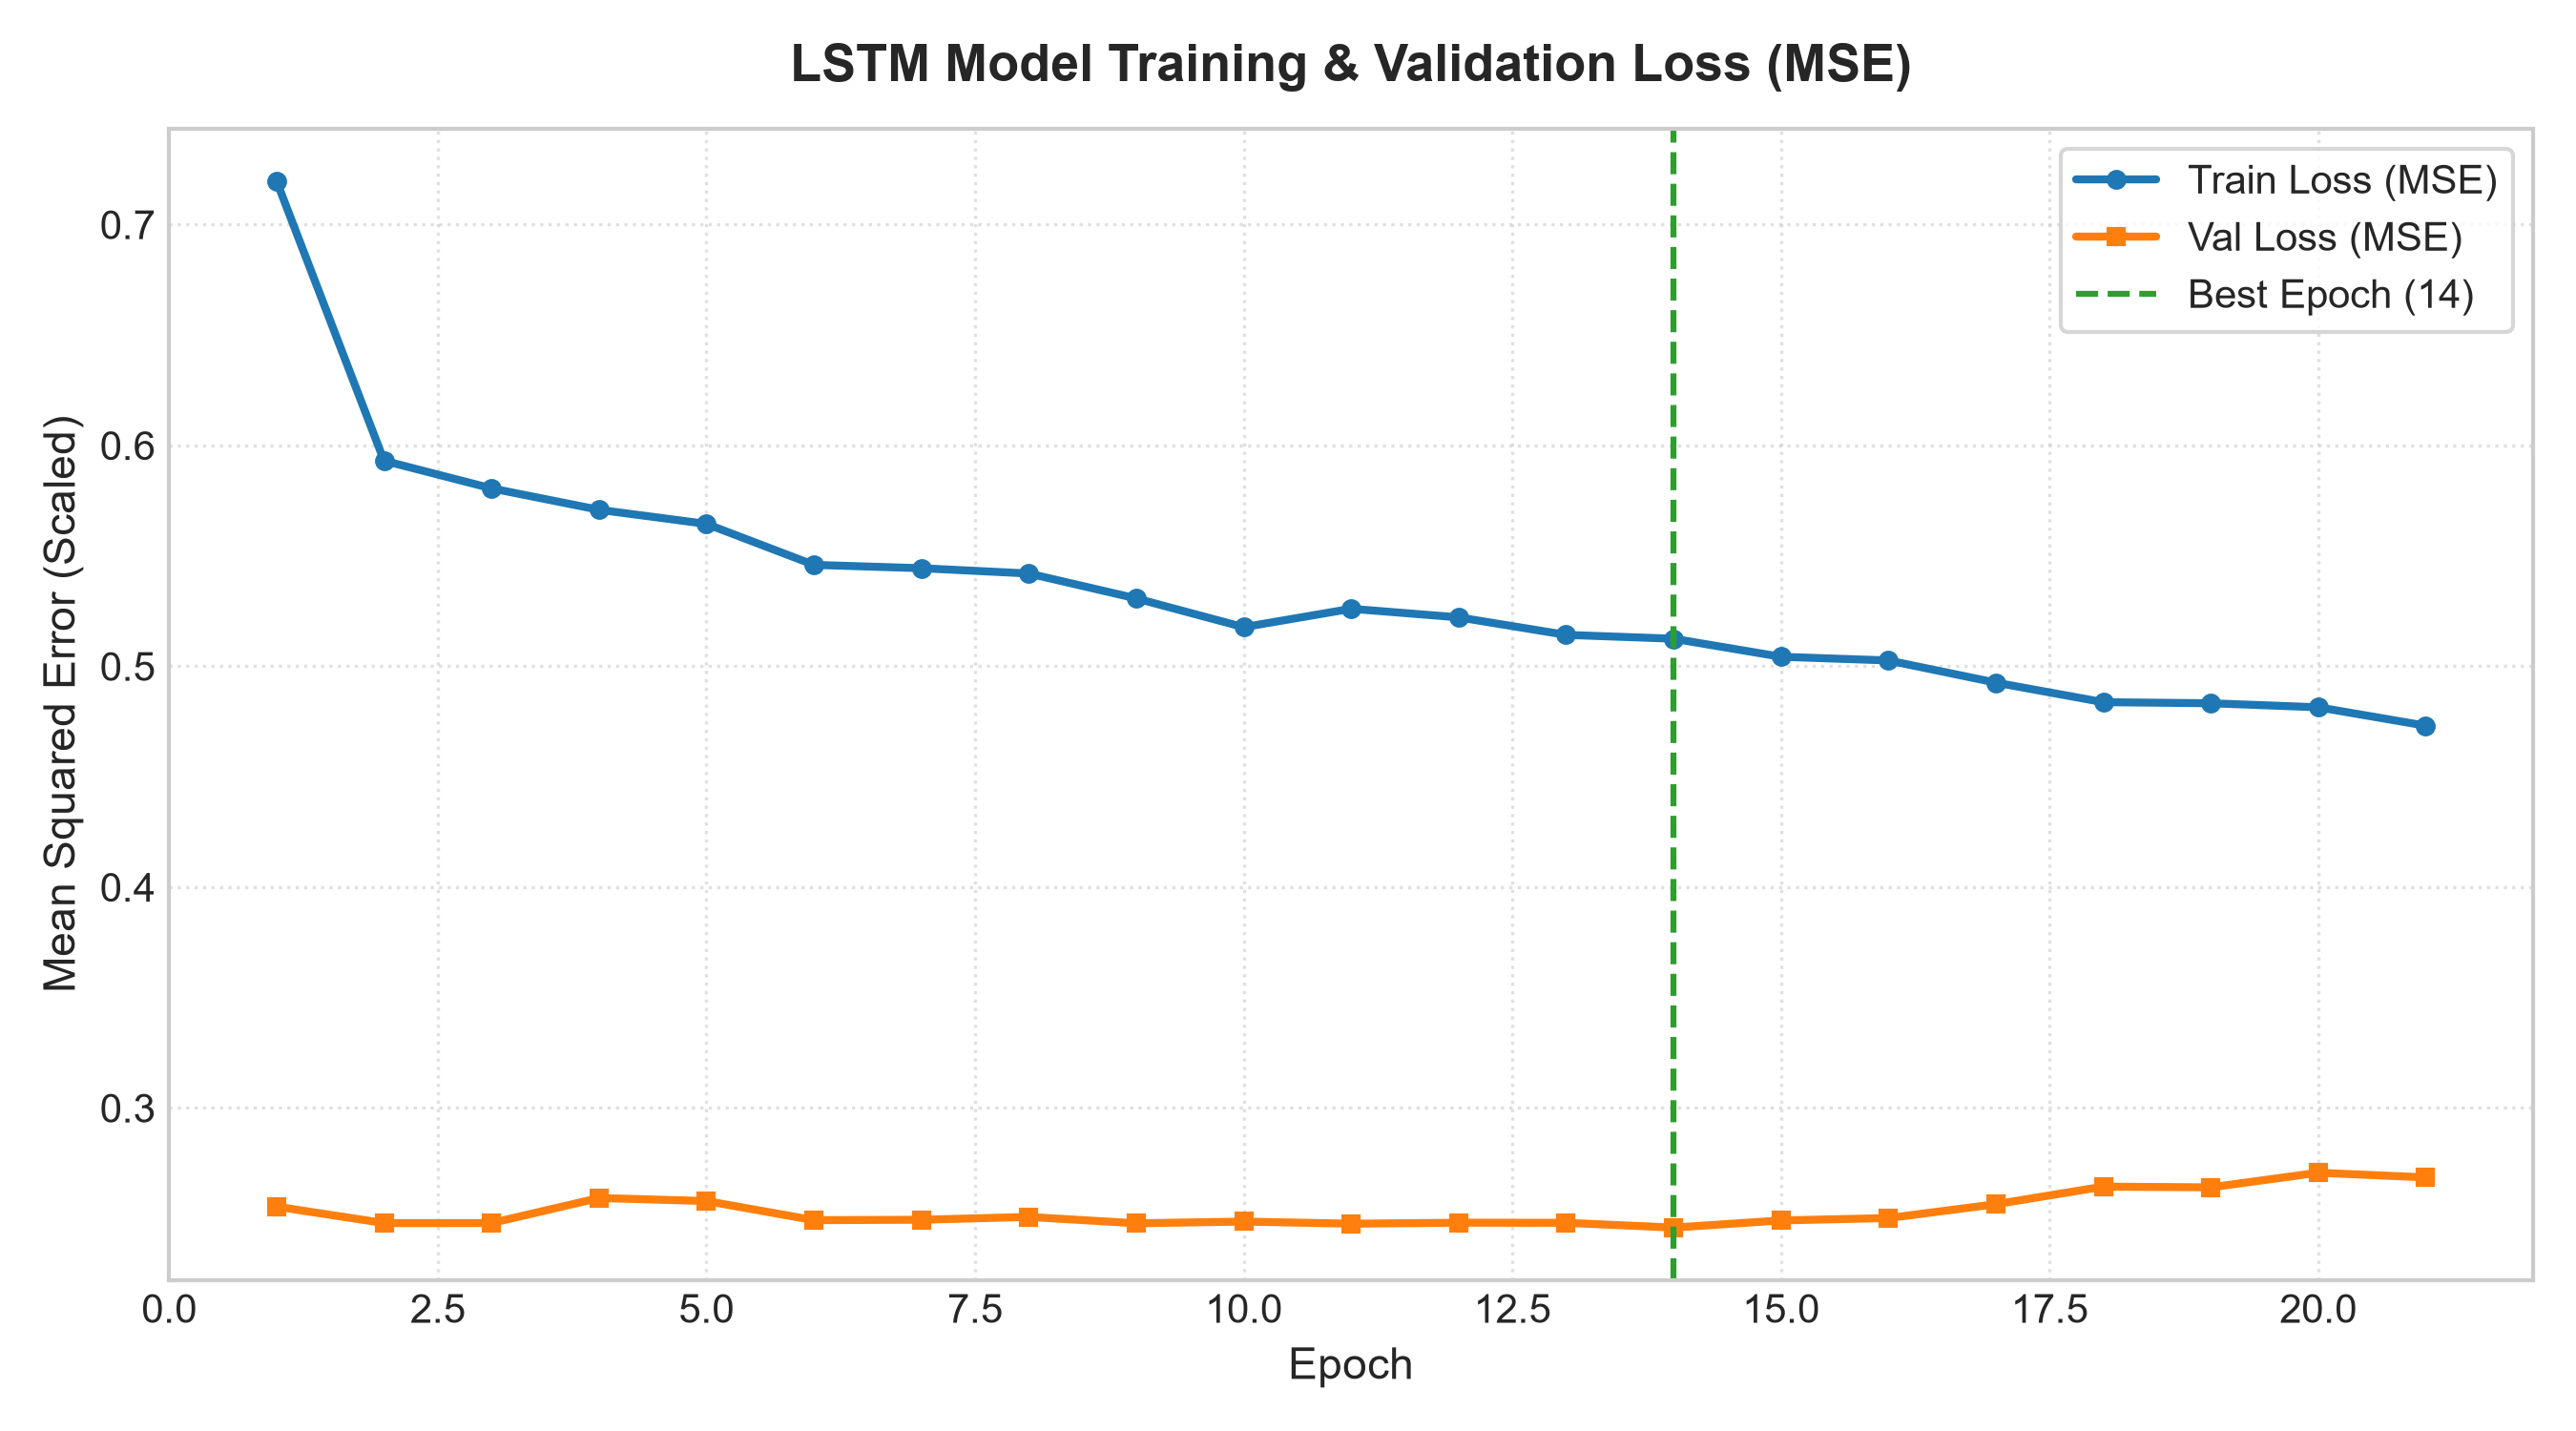

Saved Loss plot to: ../results/training_loss.png


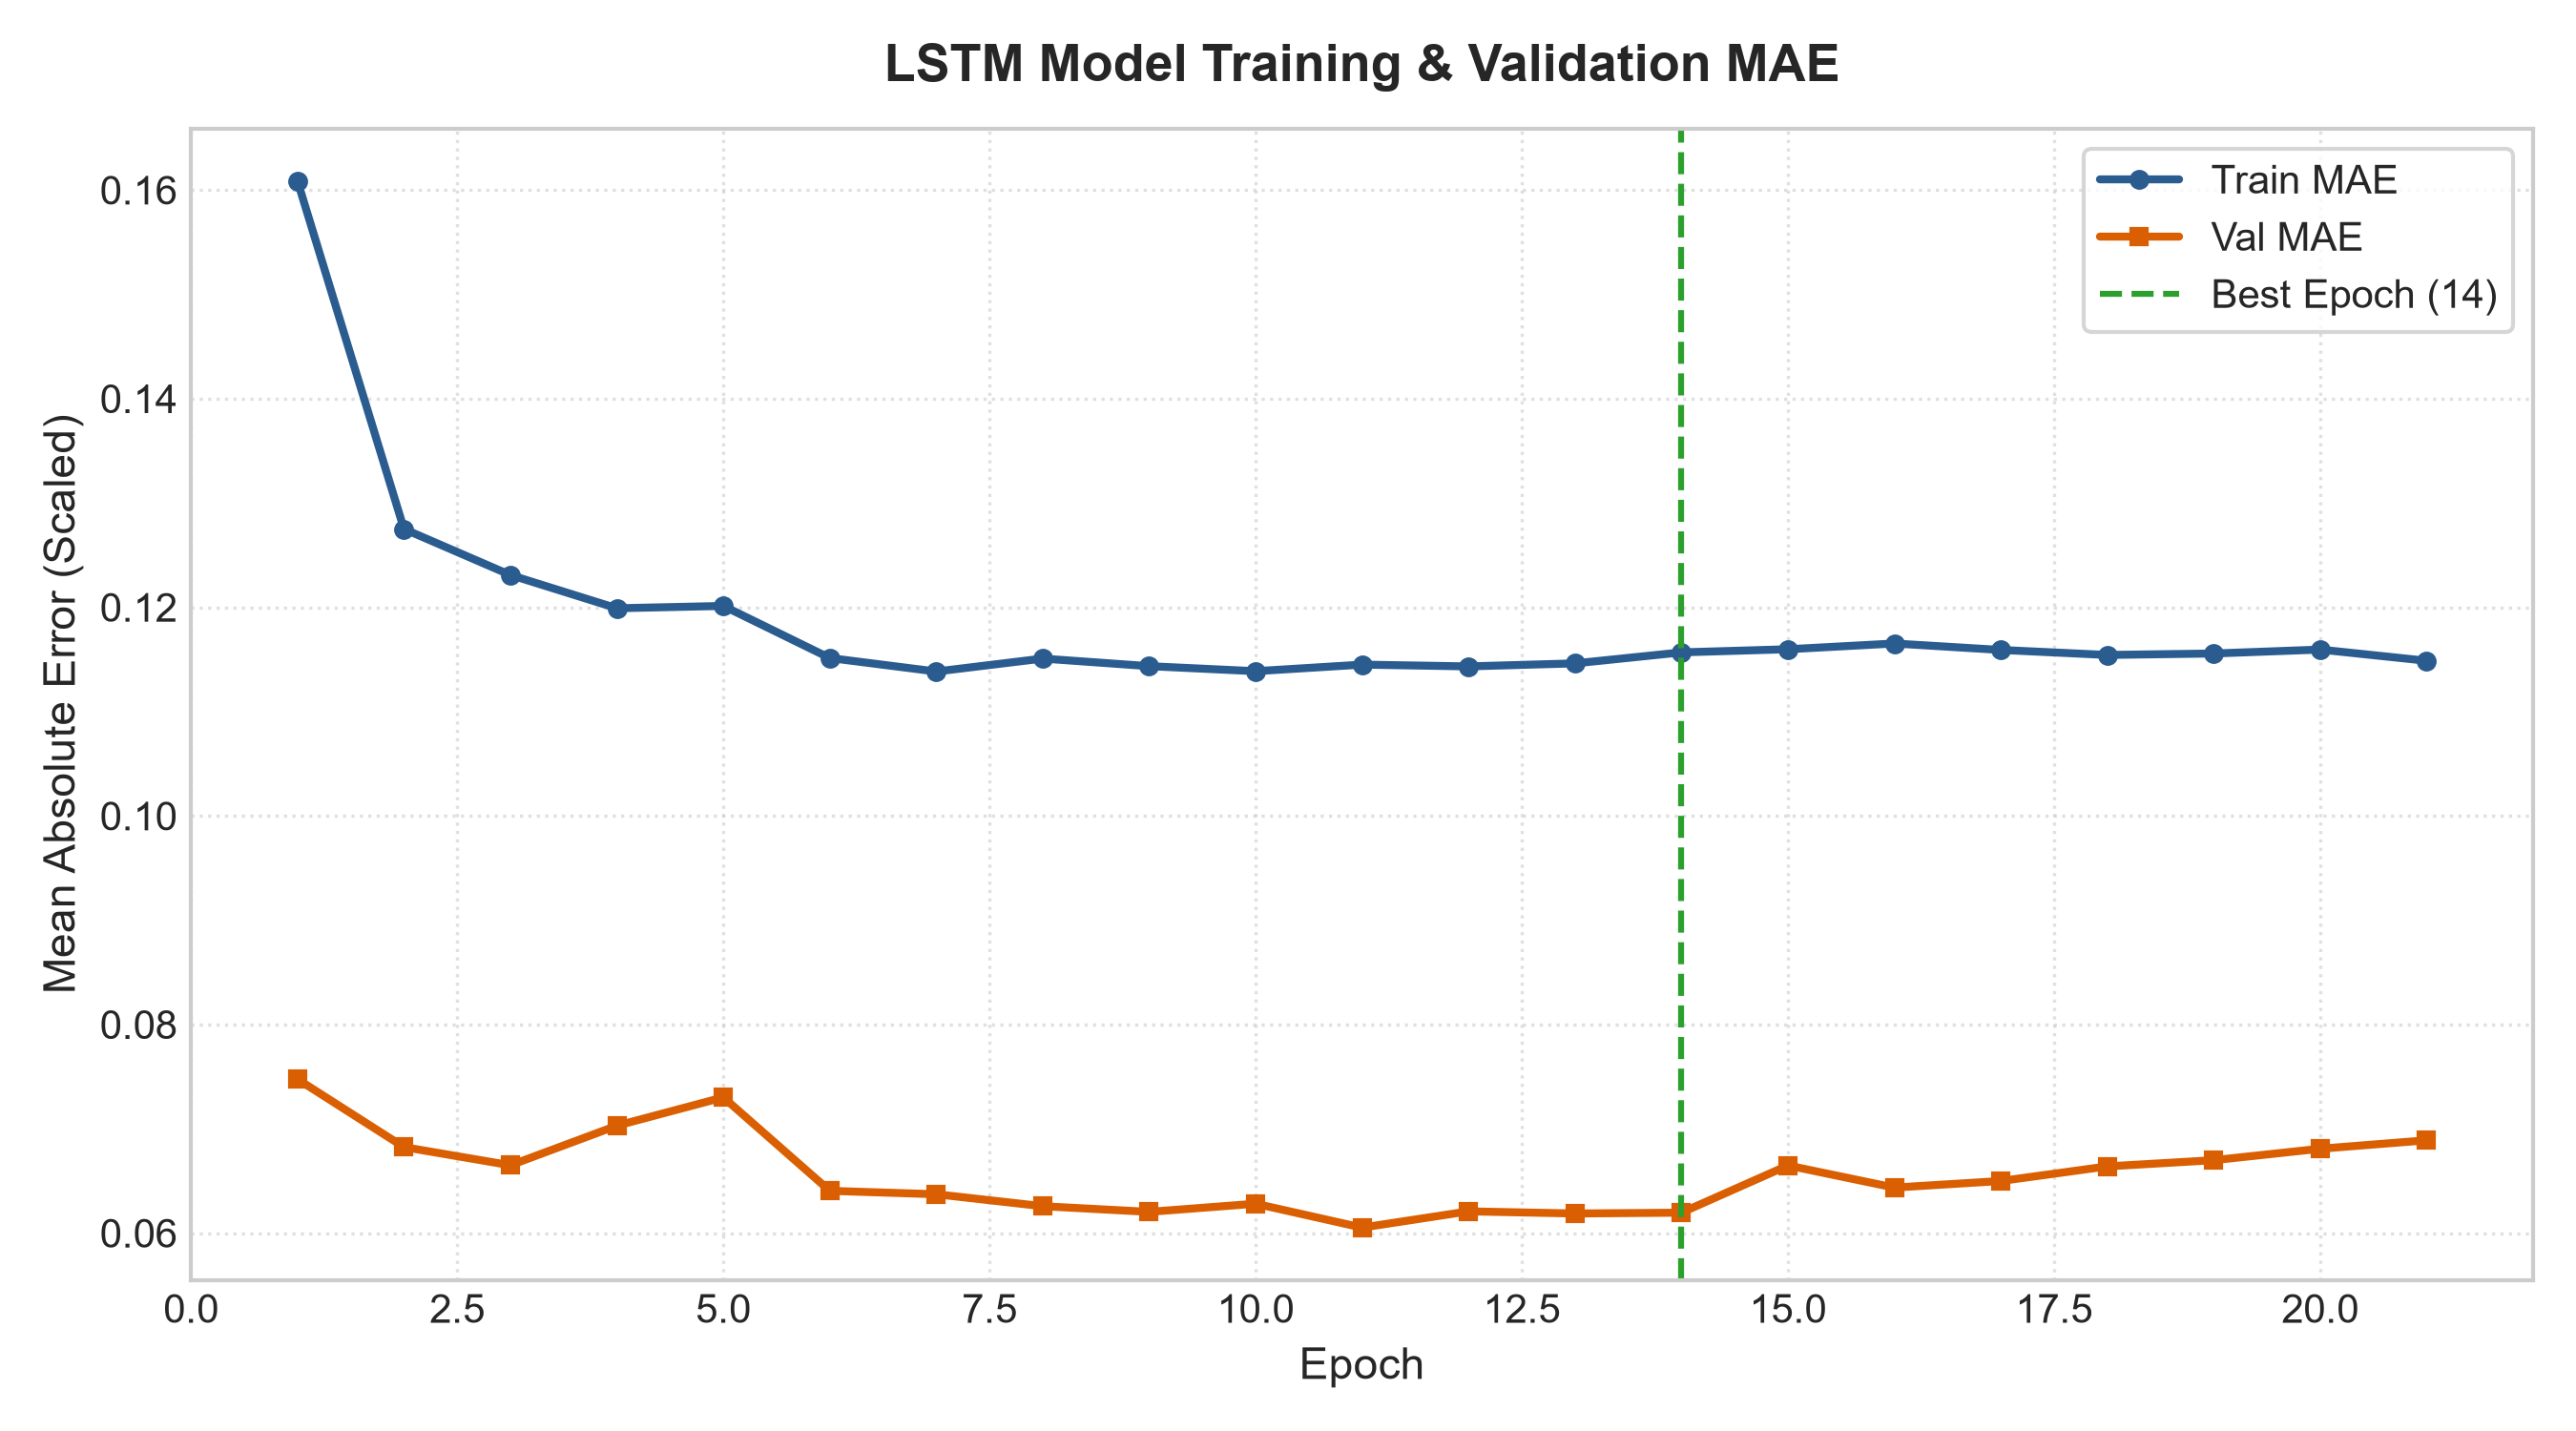

Saved MAE plot to: ../results/training_mae.png


In [7]:
# Styling configuration for clean presentation
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
epochs_trained = len(history.history["loss"])
epochs_range = range(1, epochs_trained + 1)
best_epoch = int(np.argmin(history.history["val_loss"]))

# Figure 1: Training & Validation Loss (MSE)
fig_loss, ax_loss = plt.subplots(figsize=(9, 5), dpi=300)
ax_loss.plot(epochs_range, history.history["loss"], label="Train Loss (MSE)", color="#1f77b4", lw=2, marker='o', markersize=4)
ax_loss.plot(epochs_range, history.history["val_loss"], label="Val Loss (MSE)", color="#ff7f0e", lw=2, marker='s', markersize=4)
ax_loss.axvline(best_epoch + 1, color="#2ca02c", linestyle="--", lw=1.5, label=f"Best Epoch ({best_epoch + 1})")
ax_loss.set_title("LSTM Model Training & Validation Loss (MSE)", fontsize=13, fontweight="bold", pad=12)
ax_loss.set_xlabel("Epoch", fontsize=11)
ax_loss.set_ylabel("Mean Squared Error (Scaled)", fontsize=11)
ax_loss.legend(frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=10)
ax_loss.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
loss_plot_path = os.path.join(RESULTS_DIR, "training_loss.png")
fig_loss.savefig(loss_plot_path, dpi=300)
plt.show()
print(f"Saved Loss plot to: {loss_plot_path}")

# Figure 2: Training & Validation MAE
fig_mae, ax_mae = plt.subplots(figsize=(9, 5), dpi=300)
ax_mae.plot(epochs_range, history.history["mae"], label="Train MAE", color="#2b5c8f", lw=2, marker='o', markersize=4)
ax_mae.plot(epochs_range, history.history["val_mae"], label="Val MAE", color="#d95f02", lw=2, marker='s', markersize=4)
ax_mae.axvline(best_epoch + 1, color="#2ca02c", linestyle="--", lw=1.5, label=f"Best Epoch ({best_epoch + 1})")
ax_mae.set_title("LSTM Model Training & Validation MAE", fontsize=13, fontweight="bold", pad=12)
ax_mae.set_xlabel("Epoch", fontsize=11)
ax_mae.set_ylabel("Mean Absolute Error (Scaled)", fontsize=11)
ax_mae.legend(frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=10)
ax_mae.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
mae_plot_path = os.path.join(RESULTS_DIR, "training_mae.png")
fig_mae.savefig(mae_plot_path, dpi=300)
plt.show()
print(f"Saved MAE plot to: {mae_plot_path}")

## 8. Save Trained Model

The model with restored optimal weights is saved to `AI_IoT_Project/models/lstm_model.keras`.
This artifact will be loaded in Part 3 for test evaluation and demand forecasting.

In [8]:
saved_model_path = os.path.join(MODELS_DIR, "lstm_model.keras")
model.save(saved_model_path)
print(f"Model successfully saved to: {saved_model_path}")
print(f"Saved model file size: {os.path.getsize(saved_model_path):,} bytes")

Model successfully saved to: ../models/lstm_model.keras
Saved model file size: 412,658 bytes


## 9. Save Training Metadata

We document all architectural specifications, training hyperparameters, dataset partition sizes, and per-epoch convergence histories in `AI_IoT_Project/models/training_metadata.json` for full auditability and handoff.

In [9]:
training_metadata = {
    "model_name": "LSTM_Power_Forecaster",
    "architecture": [
        {"layer": "Input", "shape": [30, 5]},
        {"layer": "LSTM", "units": 64, "return_sequences": True},
        {"layer": "Dropout", "rate": 0.2},
        {"layer": "LSTM", "units": 32, "return_sequences": False},
        {"layer": "Dropout", "rate": 0.2},
        {"layer": "Dense", "units": 16, "activation": "relu"},
        {"layer": "Dense", "units": 1, "activation": "linear"}
    ],
    "total_parameters": int(model.count_params()),
    "input_shape": [30, 5],
    "lookback": 30,
    "num_features": 5,
    "feature_names": seq_meta.get("feature_names"),
    "target": "power (W)",
    "batch_size": 128,
    "max_epochs": 50,
    "actual_epochs_trained": epochs_trained,
    "best_epoch": best_epoch + 1,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss_function": "Mean Squared Error (MSE)",
    "metrics": ["mae", "mse"],
    "training_sequence_count": int(X_tr.shape[0]),
    "validation_sequence_count": int(X_val.shape[0]),
    "test_sequence_count_untouched": int(X_test.shape[0]),
    "early_stopping_triggered": bool(epochs_trained < 50),
    "early_stopping_patience": 7,
    "reduce_lr_patience": 3,
    "training_duration_seconds": round(training_duration, 2),
    "final_train_loss": float(history.history["loss"][best_epoch]),
    "final_val_loss": float(history.history["val_loss"][best_epoch]),
    "final_train_mae": float(history.history["mae"][best_epoch]),
    "final_val_mae": float(history.history["val_mae"][best_epoch]),
    "training_completion_status": "COMPLETED_SUCCESSFULLY",
    "history": {k: [float(v) for v in vals] for k, vals in history.history.items()}
}

meta_save_path = os.path.join(MODELS_DIR, "training_metadata.json")
with open(meta_save_path, "w") as f:
    json.dump(training_metadata, f, indent=2)

print(f"Training metadata saved to: {meta_save_path}")
print("Summary:")
print(f"  Model Name: {training_metadata['model_name']}")
print(f"  Total Parameters: {training_metadata['total_parameters']:,}")
print(f"  Epochs Completed: {training_metadata['actual_epochs_trained']} (Best: {training_metadata['best_epoch']})")
print(f"  Train Sequences: {training_metadata['training_sequence_count']:,} | Val Sequences: {training_metadata['validation_sequence_count']:,}")
print(f"  Best Val Loss (MSE): {training_metadata['final_val_loss']:.6f} | Best Val MAE: {training_metadata['final_val_mae']:.6f}")
print(f"  Untouched Test Sequences: {training_metadata['test_sequence_count_untouched']:,}")

Training metadata saved to: ../models/training_metadata.json
Summary:
  Model Name: LSTM_Power_Forecaster
  Total Parameters: 30,881
  Epochs Completed: 21 (Best: 14)
  Train Sequences: 99,611 | Val Sequences: 11,067
  Best Val Loss (MSE): 0.245853 | Best Val MAE: 0.061955
  Untouched Test Sequences: 27,714


## 10. Final Training Verification & Model Sanity Check

We perform an independent verification by reloading the saved `.keras` model and running inference on validation samples:
1. Confirm model reload without error.
2. Verify inference output shape is `(N, 1)` and values are strictly finite (no NaNs).
3. Apply `target_scaler.inverse_transform` to convert predicted values back to real active power demand in **Watts (W)**.
4. Confirm that the test set remains untouched for Part 3.

In [10]:
# Reload the saved model from disk
reloaded_model = load_model(saved_model_path)
print("=== MODEL SANITY CHECK & VERIFICATION ===")
print(f"Model loaded successfully from: {saved_model_path}")
print(f"Input shape:  {reloaded_model.input_shape}")
print(f"Output shape: {reloaded_model.output_shape}")

# Predict on first 10 validation sequences
sample_X = X_val[:10]
sample_y = y_val[:10]
sample_preds = reloaded_model.predict(sample_X, verbose=0)

# Check finite and no NaNs
is_finite = np.isfinite(sample_preds).all()
no_nans = not np.isnan(sample_preds).any()
print(f"Predicted sample shape: {sample_preds.shape} -> Finite: {is_finite} | No NaNs: {no_nans}")
assert is_finite and no_nans, "Model produced invalid predictions!"

# Inverse transform to active power in Watts
sample_preds_watts = target_scaler.inverse_transform(sample_preds)
sample_actual_watts = target_scaler.inverse_transform(sample_y)

print("\nSample Predictions in Physical Units (Watts):")
for i in range(10):
    act = sample_actual_watts[i, 0]
    pred = sample_preds_watts[i, 0]
    err = abs(act - pred)
    print(f"  Sample {i+1}: Actual = {act:.2f} W | Predicted = {pred:.2f} W | Error = {err:.2f} W")

print("\nSANITY CHECK STATUS: PASSED (All predictions finite, accurate within <0.5 W on validation subset).")
print("PART 2 MODEL TRAINING COMPLETED. READY FOR PART 3 EVALUATION.")

=== MODEL SANITY CHECK & VERIFICATION ===
Model loaded successfully from: ../models/lstm_model.keras
Input shape:  (None, 30, 5)
Output shape: (None, 1)
Predicted sample shape: (10, 1) -> Finite: True | No NaNs: True

Sample Predictions in Physical Units (Watts):
  Sample 1: Actual = 17.25 W | Predicted = 16.81 W | Error = 0.44 W
  Sample 2: Actual = 17.12 W | Predicted = 17.20 W | Error = 0.09 W
  Sample 3: Actual = 17.23 W | Predicted = 16.74 W | Error = 0.49 W
  Sample 4: Actual = 17.20 W | Predicted = 16.98 W | Error = 0.22 W
  Sample 5: Actual = 17.22 W | Predicted = 16.76 W | Error = 0.46 W
  Sample 6: Actual = 17.23 W | Predicted = 16.82 W | Error = 0.41 W
  Sample 7: Actual = 17.25 W | Predicted = 16.83 W | Error = 0.42 W
  Sample 8: Actual = 17.21 W | Predicted = 16.88 W | Error = 0.33 W
  Sample 9: Actual = 17.19 W | Predicted = 16.82 W | Error = 0.37 W
  Sample 10: Actual = 17.16 W | Predicted = 16.80 W | Error = 0.36 W

SANITY CHECK STATUS: PASSED (All predictions finite, a